In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

In [3]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

In [10]:
df[categorical_columns] = df[categorical_columns].fillna('NA')

In [12]:
df[['annual_income', 'lead_score']] = df[['annual_income', 'lead_score']].fillna(0.0)

In [13]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [14]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [23]:
X_train = df_train.drop(columns=['converted'])
X_val = df_val.drop(columns=['converted'])
X_test = df_test.drop(columns=['converted'])

In [24]:
y_train = df_train.converted
y_val = df_val.converted
y_test = df_test.converted

In [32]:
numerical_columns = list(df.dtypes[df.dtypes != 'str'].index)
numerical_columns = numerical_columns[:-1]

In [27]:
from IPython import display

In [28]:
from sklearn.metrics import roc_curve, auc

In [35]:
auc_list = []
for n in numerical_columns:
    fpr, tpr, thresholds = roc_curve(y_train, X_train[n])
    tmp_auc = auc(fpr, tpr)
    if tmp_auc < 0.5:
        fpr, tpr, thresholds = roc_curve(y_train, -X_train[n])
        tmp_auc = auc(fpr, tpr)
    auc_list.append(tmp_auc)
dict(zip(numerical_columns, auc_list))

{'annual_income': 0.6081977776250831,
 'number_of_courses_viewed': 0.7229894623989618,
 'interaction_count': 0.7649203047563227,
 'lead_score': 0.7882254810906102}

In [37]:
def train(X_train, y_train, C=1.0):
    dicts = df_train[categorical_columns + numerical_columns].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [38]:
dv, model = train(X_train, y_train)

In [41]:
def predict(df, dv, model):
    dicts = df[categorical_columns + numerical_columns].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [42]:
y_pred = predict(X_val, dv, model)

In [46]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)
np.round(auc(fpr, tpr), 3)

np.float64(0.732)

In [50]:
from sklearn.metrics import precision_recall_curve

In [51]:
precision, recall, thresholds = precision_recall_curve(y_val, y_pred)

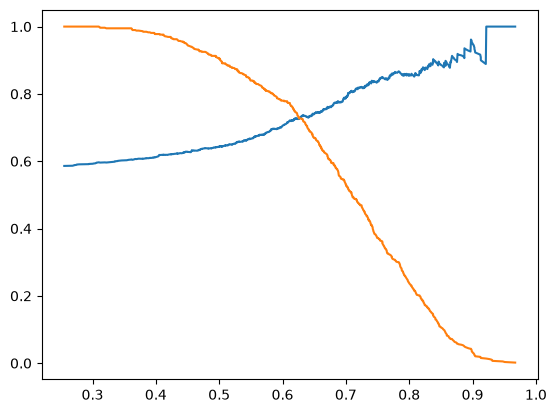

In [57]:
plt.plot(thresholds, precision[:-1])
plt.plot(thresholds, recall[:-1])
plt.show()

In [58]:
from sklearn.metrics import f1_score

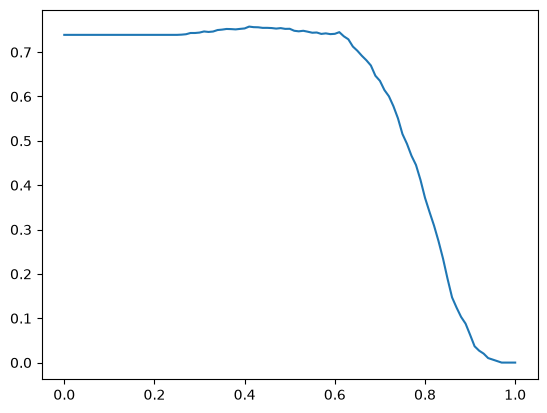

In [64]:
thresholds = np.linspace(0, 1, 101)
f1_list = []
max_f1_threshold = None
max_f1 = 0
for t in thresholds:
    tmp_f1 = f1_score(y_val, y_pred >= t)
    f1_list.append(tmp_f1)
    if tmp_f1 > max_f1:
        max_f1 = tmp_f1
        max_f1_threshold = t
plt.plot(thresholds, f1_list)
plt.show()

In [66]:
max_f1_threshold

np.float64(0.41000000000000003)

In [68]:
!pip install tqdm


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [73]:
from tqdm.auto import tqdm
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

In [74]:
n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
